# Digital Image Processing — Week 5 · Task 4

**Grup: Nmertgules ve Iliya**

Kendi fonksiyonlarımızla **BGR → YCrCb, HSV, CIELAB** dönüşümleri ve OpenCV ile sayısal karşılaştırma. PDF'deki **HSI ve normalize rgb** de ek olarak uygulanır; OpenCV'de doğrudan HSI/normalize rgb dönüşümü olmadığı için bunlarda formül/invariant kontrolleri yapılır. Gri dönüşüm ayrı Task 3'tedir ve değiştirilmez.

Uygulamalar [color_conversions.py](color_conversions.py) içindedir; hazır renk dönüşümü çağırmazlar. OpenCV'nin 8-bit temsiline sıfır hata ile uymak için sabit nokta katsayıları ve formüllerden üretilen gamma/küpkök tabloları kullanılır. Kaynaklar modülün başında verilmiştir. Python kullanıldığı için C++ için belirtilen fonksiyon pointer'ı koşulu uygulanmaz; dönüşümler fonksiyon referanslarıyla seçilir.


In [1]:
from pathlib import Path
import sys, json
import cv2
import numpy as np
import matplotlib.pyplot as plt
ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p/'week4/assets/rocket.jpg').is_file()), None)
if ROOT is None:
    raise FileNotFoundError('Repoyu bütünüyle indirin ve repo içinden çalıştırın.')
WEEK = ROOT/'week5'
OUT = WEEK/'results'
OUT.mkdir(exist_ok=True)
sys.path.insert(0, str(WEEK))
print('OpenCV:', cv2.__version__, '| NumPy:', np.__version__)


OpenCV: 5.0.0 | NumPy: 2.5.4


In [2]:
from color_conversions import to_ycrcb, to_hsv, to_lab, to_hsi, to_normalized_rgb
image = cv2.imread(str(ROOT/'week4/assets/rocket.jpg'))
if image is None: raise FileNotFoundError('rocket.jpg')
# Kendi fonksiyonumuz ve bağımsız OpenCV referansı.
conversions = {
    'YCrCb': (to_ycrcb, cv2.COLOR_BGR2YCrCb, ['Y', 'Cr', 'Cb']),
    'HSV': (to_hsv, cv2.COLOR_BGR2HSV, ['H (0–179)', 'S', 'V']),
    'Lab': (to_lab, cv2.COLOR_BGR2Lab, ['L (0–255)', 'a + 128', 'b + 128']),
}
metrics = {}
results = {}
for name, (manual, reference_code, labels) in conversions.items():
    result = manual(image)
    reference = cv2.cvtColor(image, reference_code)
    difference = np.abs(result.astype(np.int16)-reference.astype(np.int16))
    metrics[name] = {'sum_absolute_error': int(difference.sum()),
                     'max_absolute_error': int(difference.max()),
                     'mean_absolute_error': float(difference.mean()),
                     'different_pixels': int(np.count_nonzero(np.any(difference != 0, axis=-1)))}
    assert metrics[name]['sum_absolute_error'] == 0
    results[name] = result
print(json.dumps(metrics, indent=2))


{
  "YCrCb": {
    "sum_absolute_error": 0,
    "max_absolute_error": 0,
    "mean_absolute_error": 0.0,
    "different_pixels": 0
  },
  "HSV": {
    "sum_absolute_error": 0,
    "max_absolute_error": 0,
    "mean_absolute_error": 0.0,
    "different_pixels": 0
  },
  "Lab": {
    "sum_absolute_error": 0,
    "max_absolute_error": 0,
    "mean_absolute_error": 0.0,
    "different_pixels": 0
  }
}


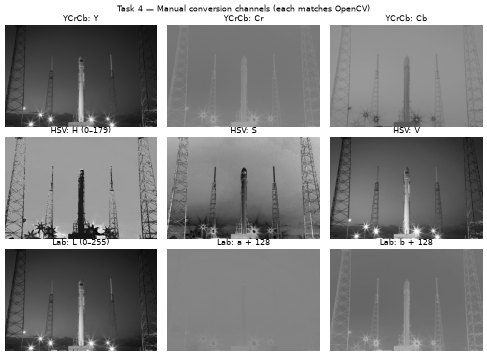

In [3]:
fig, axes = plt.subplots(3, 3, figsize=(11, 8))
for row, (name, (_, _, labels)) in enumerate(conversions.items()):
    for j, label in enumerate(labels):
        axes[row,j].imshow(results[name][...,j], cmap='gray', vmin=0, vmax=179 if name=='HSV' and j==0 else 255)
        axes[row,j].set_title(f'{name}: {label}')
        axes[row,j].axis('off')
fig.suptitle('Task 4 — Manual conversion channels (each matches OpenCV)')
fig.tight_layout()
fig.savefig(OUT/'task4_channels.png', dpi=90)
plt.show()


In [4]:
# Siyah/beyaz, saf renkler ve nötr griler: bölme/sıfır ve kanal sırası kontrolleri.
known = np.array([[[0,0,0],[255,255,255],[255,0,0],[0,255,0],[0,0,255]]], np.uint8)
for name, (manual, ref, _) in conversions.items():
    assert np.array_equal(manual(known), cv2.cvtColor(known,ref))
normalized = to_normalized_rgb(image)
hsi = to_hsi(image)
nonblack = image.sum(-1) > 0
assert np.allclose(normalized[nonblack].sum(-1), 1)
assert np.all((hsi[...,0] >= 0) & (hsi[...,0] < 360+1e-8))
assert np.all((hsi[...,1:] >= -1e-12) & (hsi[...,1:] <= 1+1e-12))
assert np.allclose(to_hsi(known)[0,2:,0], [240,120,0])
assert np.allclose(to_normalized_rgb(known)[0,0], 0)
assert np.allclose(to_hsi(known)[0,0], 0)
print('Bilinen renkler, siyah, HSI ve normalize rgb formül kontrolleri geçti.')
# Tüm 24-bit BGR renklerini 256 küçük parti halinde kontrol et; yüksek bellek gerekmez.
g, r = np.indices((256,256), dtype=np.uint8)
exhaustive = {name: {'tested_colors':0, 'sum_absolute_error':0, 'max_absolute_error':0} for name in conversions}
for blue in range(256):
    batch = np.stack((np.full_like(g,blue),g,r),-1)
    for name,(manual,ref,_) in conversions.items():
        d = np.abs(manual(batch).astype(np.int16)-cv2.cvtColor(batch,ref).astype(np.int16))
        exhaustive[name]['tested_colors'] += 256*256
        exhaustive[name]['sum_absolute_error'] += int(d.sum())
        exhaustive[name]['max_absolute_error'] = max(exhaustive[name]['max_absolute_error'],int(d.max()))
for m in exhaustive.values(): assert m['sum_absolute_error']==0
report = {'opencv_version':cv2.__version__, 'image_results':metrics, 'all_colors':exhaustive,
          'supplemental': {'HSI':'formula checks passed; no direct cvtColor reference',
                           'normalized_rgb':'sum/nonblack and black checks passed; no direct cvtColor reference'}}
(OUT/'task4_metrics.json').write_text(json.dumps(report,indent=2),encoding='utf-8')
print(json.dumps(exhaustive,indent=2))


Bilinen renkler, siyah, HSI ve normalize rgb formül kontrolleri geçti.
{
  "YCrCb": {
    "tested_colors": 16777216,
    "sum_absolute_error": 0,
    "max_absolute_error": 0
  },
  "HSV": {
    "tested_colors": 16777216,
    "sum_absolute_error": 0,
    "max_absolute_error": 0
  },
  "Lab": {
    "tested_colors": 16777216,
    "sum_absolute_error": 0,
    "max_absolute_error": 0
  }
}


## Sonuç

Üç OpenCV karşılaştırması için hata, tüm kanallardaki mutlak farkların toplamıdır. Ödev görüntüsünde ve tüm 24-bit renklerde sıfır çıktı (test edilen OpenCV sürümü sayısal raporda). HSI/normalize rgb için OpenCV sonucu varmış gibi sıfır hata iddiası yapılmaz.

CIELAB'da PDF'nin yuvarlatılmış matrisini doğrudan kullanmak yerine OpenCV'nin D65 sabitleri ve uint8 ölçeği kullanılır. YCrCb'de Y/Cr/Cb kanal sırası ve HSV'de H/2 kodlaması dikkate alınır. Bunlar fiziksel formüllerin aynı olmasının tek başına bit düzeyinde eşitlik sağlamamasının nedenleridir.
